## 1. Imports and shared code

In [1]:
import sys
import time
from pathlib import Path
from itertools import product

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from joblib import Parallel, delayed
from lightgbm import LGBMClassifier
from sklearn.metrics import roc_auc_score, accuracy_score

sys.path.insert(0, str(Path("../../src").resolve()))
from recplay.windowed import rqa_frame, rrc_frame, window_surrogates, euclidean_distance
from recplay.analogue import analogue_frame

## 2. Data

In [2]:
# Load FRED monthly series
DATA_DIR = Path("../../data/raw/fred")  # relative to notebooks/02_macro/, where this notebook lives

def load_csv(name: str) -> pd.Series:
    df = pd.read_csv(DATA_DIR / f"{name}.csv", parse_dates=["observation_date"], index_col="observation_date")
    return df[name].astype(float)

cpi = load_csv("CPIAUCSL")
unrate = load_csv("UNRATE")
fedfunds = load_csv("FEDFUNDS")

for s in (cpi, unrate, fedfunds):
    print(f"{s.name:9s} {s.index.min().date()} to {s.index.max().date()}  n={len(s)}  missing={s.isna().sum()}")

CPIAUCSL  1947-01-01 to 2026-09-01  n=957  missing=1
UNRATE    1948-01-01 to 2026-09-01  n=945  missing=1
FEDFUNDS  1954-07-01 to 2026-09-01  n=867  missing=0


In [3]:
# Impute October 2025 as Bureau of labor stats did not collect CPI or household-survey data during the shutdown

cpi_m, unrate_m, fedfunds_m = (s.asfreq("MS") for s in (cpi, unrate, fedfunds))

cpi_imputed = cpi_m.isna()
unrate_imputed = unrate_m.isna()

print("Imputing CPI at:", list(cpi_m.index[cpi_imputed].date))
print("Imputing UNRATE at:", list(unrate_m.index[unrate_imputed].date))
assert not fedfunds_m.isna().any()

cpi_clean = np.exp(np.log(cpi_m).interpolate(method="linear", limit_area="inside"))  # geometric for a price level
unrate_clean = unrate_m.interpolate(method="linear", limit_area="inside")
fedfunds_clean = fedfunds_m

print(pd.DataFrame({"CPIAUCSL": cpi_clean, "UNRATE": unrate_clean}).loc["2025-09":"2025-11"])

Imputing CPI at: [datetime.date(2025, 10, 1)]
Imputing UNRATE at: [datetime.date(2025, 10, 1)]


,CPIAUCSL,UNRATE
observation_date,,
2025-09-01,324.245000,4.40
2025-10-01,324.653742,4.45
2025-11-01,325.063000,4.50


In [4]:
# CPI level turned to YoY inflation, on the full CPI history (1947-), thus no lost months at the 1954 start
# YoY inflation instead of MoM inflation, avoiding overly noisy periods 
inflation = (100 * (np.log(cpi_clean) - np.log(cpi_clean.shift(12)))).rename("INFLATION")

# A YoY value is imputed if either of its two CPI inputs was imputed
inflation_imputed = cpi_imputed | cpi_imputed.shift(12, fill_value=False)

inflation = inflation.dropna()
inflation_imputed = inflation_imputed.loc[inflation.index]
print(f"INFLATION {inflation.index.min().date()} to {inflation.index.max().date()}  n={len(inflation)}")

INFLATION 1948-01-01 to 2026-09-01  n=945


In [5]:
# Common window, checks
macro = pd.concat([inflation, unrate_clean, fedfunds_clean], axis=1, join="inner")
macro["IMPUTED"] = (inflation_imputed | unrate_imputed).loc[macro.index]

assert macro.index.is_monotonic_increasing and macro.index.is_unique
assert len(macro.asfreq("MS")) == len(macro), "gap in monthly index"
assert not macro.isna().any().any(), "NaN left after cleaning"

print(f"{macro.index.min().date()} to {macro.index.max().date()}  n={len(macro)}")
print("Imputed rows:", list(macro.index[macro["IMPUTED"]].date))
macro.head()

1954-07-01 to 2026-09-01  n=867
Imputed rows: [datetime.date(2025, 10, 1)]


,INFLATION,UNRATE,FEDFUNDS,IMPUTED
observation_date,,,,
1954-07-01,0.260951,5.8,0.80,False
1954-08-01,0.000000,6.0,1.22,False
1954-09-01,-0.297952,6.1,1.07,False
1954-10-01,-0.857095,5.7,0.85,False
1954-11-01,-0.261048,5.3,0.83,False


In [6]:
# Monthly inflation on the full CPI history, so its lags are complete from 1954-07; YoY is exactly its 12-month sum
pi = (100 * np.log(cpi_clean).diff()).rename("PI")
macro["PI"] = pi.loc[macro.index]
assert np.allclose(pi.rolling(12).sum().loc[macro.index], macro.INFLATION)

## 3. Targets and evaluation calendar

In [7]:
HORIZONS = [1, 3, 6, 12]
SCREEN_YEARS = (1975, 1999)
FINAL_YEARS = (2000, 2026)
yoy = macro.INFLATION

# Row t is 1 if YoY h months later is strictly higher than at t
targets = {h: (yoy.shift(-h) > yoy).astype(int)[yoy.shift(-h).notna()] for h in HORIZONS}
label_imputed = {h: (macro.IMPUTED | macro.IMPUTED.shift(-h, fill_value=False)).loc[targets[h].index] for h in HORIZONS}


def blocks(h, first_year, last_year):
    """The model for year Y is fitted at the start of Y, on rows whose h-month label is known by then."""
    idx = targets[h].index
    for year in range(first_year, last_year + 1):
        start = pd.Timestamp(year, 1, 1)
        train = idx.shift(h, freq="MS") <= start
        test = idx.year == year
        if not test.any():
            continue
        assert idx[train].max() + pd.DateOffset(months=h) <= start <= idx[test].min()
        yield train, test


def scored_rows(h, first_year, last_year):
    test = np.zeros(len(targets[h]), bool)
    for _, t in blocks(h, first_year, last_year):
        test |= t
    return test & ~label_imputed[h].to_numpy()


def make_classifier():
    return LGBMClassifier(n_estimators=200, learning_rate=0.05, max_depth=3, num_leaves=7, min_child_samples=20,
                          subsample=0.8, subsample_freq=1, colsample_bytree=0.8, random_state=0, n_jobs=1, verbose=-1)


def evaluate(X, h, first_year, last_year):
    y = targets[h]
    has = y.index.isin(X.index)
    X = X.reindex(y.index)
    pred = pd.Series(np.nan, index=y.index)
    for train, test in blocks(h, first_year, last_year):
        train &= has
        assert has[test].all()
        model = make_classifier().fit(X[train], y[train])
        pred[test] = model.predict_proba(X[test])[:, 1]
    rows = scored_rows(h, first_year, last_year)
    p, t = pred[rows], y[rows]
    return {"auc": roc_auc_score(t, p), "acc": accuracy_score(t, p >= 0.5), "n_test": int(rows.sum())}, p


def auc_gain(p_new, p_base, labels, n=2000):
    """AUC(p_new) - AUC(p_base) on the same months, with a 95% interval from resampling whole calendar years."""
    t = labels[p_new.index]
    years = p_new.index.year
    groups = [np.flatnonzero(years == yr) for yr in np.unique(years)]
    rng = np.random.default_rng(0)
    diffs = []
    for _ in range(n):
        i = np.concatenate([groups[g] for g in rng.integers(0, len(groups), len(groups))])
        diffs.append(roc_auc_score(t.iloc[i], p_new.iloc[i]) - roc_auc_score(t.iloc[i], p_base.iloc[i]))
    return roc_auc_score(t, p_new) - roc_auc_score(t, p_base), *np.quantile(diffs, [0.025, 0.975])


print(pd.DataFrame({h: {"screening rows": scored_rows(h, *SCREEN_YEARS).sum(),
                        "final rows": scored_rows(h, *FINAL_YEARS).sum()} for h in HORIZONS}))

,1,3,6,12
screening rows,300,300,300,300
final rows,318,316,313,308


## 4. Lag and base-effect features

In [8]:
def lagged_values(data=macro):
    dpi = data.INFLATION.diff()
    return pd.concat({f"dpi_lag{k}": dpi.shift(k) for k in range(12)}, axis=1).join(data[["INFLATION", "UNRATE", "FEDFUNDS"]])


def base_effect(h, pi=pi):
    """π_{t-11} + ... + π_{t-12+h}: the monthly inflation that leaves the YoY sum over the next h months."""
    return pi.rolling(h).sum().shift(12 - h)


def lags_base(h, data=macro, pi=pi):
    pi_lags = pd.concat({f"pi_lag{k}": pi.shift(k) for k in range(13)}, axis=1)
    return lagged_values(data).join(pi_lags).join(base_effect(h, pi).rename("base_effect"))


# YoY(t+h) - YoY(t) = (π_{t+1} + ... + π_{t+h}) - base effect, so only the first sum is unknown at t
for h in HORIZONS:
    gap = (yoy.shift(-h) - yoy) - (pi.rolling(h).sum().shift(-h) - base_effect(h)).loc[macro.index]
    assert gap.abs().max() < 1e-9

lag_base_features = {h: lags_base(h) for h in HORIZONS}

## 5. Monthly-inflation RP features

Delete `data/processed/monthly_pi/` after changing feature code.

In [9]:
CACHE_DIR = Path("../../data/processed/monthly_pi")
SURR_DIR = CACHE_DIR / "iaaft"
SERIES = {"pi": "PI"}
RQA_KEEP = ["DET", "L", "ENTR", "LAM", "DET3_DET2", "K2_lines", "RR_last"]
THEILER, RRC_DELTA, N_SURR = 1, 0.05, 19
KEYS = ["W", "m", "tau", "rr"]
WINDOW_COLS = [f"pi_{k}" for k in RQA_KEEP] + ["pi_RRc", "pi_dRRc", "pi_mean", "pi_std"]


def rp_features(W, m, tau, rr, data=macro) -> pd.DataFrame:
    df = rqa_frame(data, SERIES, {}, W, m, tau, rr, euclidean_distance, THEILER)
    # ε comes from the target rate, so the RR of the whole window carries no information
    assert df["pi_RR"].std() < 1e-3
    return df


def rrc_features(W, m, tau, data=macro, surrogates=None) -> pd.DataFrame:
    if surrogates is None:
        surrogates = window_surrogates(data, SERIES, W, N_SURR)
    return rrc_frame(data, SERIES, {}, W, m, tau, euclidean_distance, surrogates, THEILER, RRC_DELTA)


def moments(W, data=macro) -> pd.DataFrame:
    """Mean and std of the raw window; the RP itself only sees the z-scored window."""
    x = data.PI.rolling(W)
    return pd.DataFrame({"pi_mean": x.mean(), "pi_std": x.std(ddof=0)}).iloc[W - 1 :]


def cached(path, build, load=True):
    if path.exists():
        return pd.read_pickle(path) if load else None
    path.parent.mkdir(parents=True, exist_ok=True)
    obj = build()
    tmp = path.with_suffix(".tmp")
    pd.to_pickle(obj, tmp)
    tmp.replace(path)
    return obj if load else None


def load_surrogates(W, load=True):
    return cached(SURR_DIR / f"W{W}_n{N_SURR}.pkl", lambda: window_surrogates(macro, SERIES, W, N_SURR), load)


def load_rrc(W, m, tau, load=True):
    return cached(CACHE_DIR / "rrc" / f"W{W}_m{m}_tau{tau}.pkl",
                  lambda: rrc_features(W, m, tau, surrogates=load_surrogates(W)), load)


def load_rqa(W, m, tau, rr, load=True):
    return cached(CACHE_DIR / "rqa" / f"W{W}_m{m}_tau{tau}_rr{rr:.2f}.pkl", lambda: rp_features(W, m, tau, rr), load)


def load_window_features(W, m, tau, rr) -> pd.DataFrame:
    return load_rqa(W, m, tau, rr).join(load_rrc(W, m, tau)).join(moments(W))[WINDOW_COLS]


rp_grid = [(W, m, tau, rr) for W, (m, tau), rr in product([36, 60, 120], [(1, 1), (2, 1), (3, 1), (2, 3), (3, 3)],
                                                          [0.05, 0.10, 0.20])]
assert len(rp_grid) == 45
rrc_keys = sorted({(W, m, tau) for W, m, tau, _ in rp_grid}, key=lambda k: -k[0])
analog_keys = sorted({(m, tau, rr) for _, m, tau, rr in rp_grid})

In [10]:
# Phases, so no two jobs build the same cache file; RRc does not depend on rr
t0 = time.perf_counter()
Parallel(n_jobs=-1)(delayed(load_surrogates)(W, load=False) for W in sorted({k[0] for k in rrc_keys}))
Parallel(n_jobs=-1)(delayed(load_rrc)(*k, load=False) for k in rrc_keys)
Parallel(n_jobs=-1)(delayed(load_rqa)(*cfg, load=False) for cfg in rp_grid)
window_features = {cfg: load_window_features(*cfg) for cfg in rp_grid}
print(f"{len(window_features)} window RP configurations in {time.perf_counter() - t0:.0f} s")

45 window RP configurations in 45 s


In [11]:
# Analogues search the whole history up to t, so they depend on (m, tau, rr) but not on W
t0 = time.perf_counter()
analog_features = {k: analogue_frame(macro.PI, macro.INFLATION, *k, HORIZONS) for k in analog_keys}
print(f"{len(analog_features)} analogue configurations in {time.perf_counter() - t0:.0f} s")

15 analogue configurations in 3 s


## 6. RRc report

In [12]:
rrc_choices = pd.Series({
    "Theiler w": THEILER,
    "edge fraction δ": RRC_DELTA,
    "neighbourhood": "8-neighbour",
    "distance": "Euclidean, z-scored window of monthly inflation",
    "surrogate": f"IAAFT, {N_SURR} per window, seeded by (W, end month, series)",
    "statistic": "dRRc = RRc − mean surrogate RRc",
})
print(rrc_choices.to_string())

rows = []
for k in rrc_keys:
    df = load_rrc(*k)
    rows.append({**dict(zip(["W", "m", "tau"], k)), "RRc": df.pi_RRc.median(), "RRc_sur": df.pi_RRc_sur.median(),
                 "dRRc": df.pi_dRRc.median(), "below all surrogates": (df.pi_RRc_pct == 0).mean(),
                 "above all surrogates": (df.pi_RRc_pct == 1).mean()})
rrc_report = pd.DataFrame(rows).set_index(["W", "m", "tau"]).sort_index()
rrc_report

Theiler w                                                          1
edge fraction δ                                                 0.05
neighbourhood                                            8-neighbour
distance             Euclidean, z-scored window of monthly inflation
surrogate          IAAFT, 19 per window, seeded by (W, end month,...
statistic                            dRRc = RRc − mean surrogate RRc


RRc   RRc_sur  ...  below all surrogates  above all surrogates
W   m tau                      ...                                            
36  1 1    0.212698  0.186842  ...              0.016827              0.162260
    2 1    0.236975  0.206148  ...              0.038462              0.132212
      3    0.240530  0.202602  ...              0.026442              0.144231
    3 1    0.258467  0.209494  ...              0.039663              0.138221
      3    0.254023  0.210526  ...              0.025240              0.125000
60  1 1    0.139548  0.106913  ...              0.022277              0.162129
    2 1    0.146113  0.126042  ...              0.024752              0.162129
      3    0.151003  0.113656  ...              0.022277              0.153465
    3 1    0.169087  0.142914  ...              0.027228              0.159653
      3    0.141859  0.119037  ...              0.019802              0.153465
120 1 1    0.056162  0.028907  ...              0.028075              0.312834
    2 1    0.057328  0.036312  ...              0.013369              0.267380
      3    0.057177  0.035925  ...              0.018717              0.271390
    3 1    0.079241  0.046986  ...              0.021390              0.283422
      3    0.076075  0.049849  ...              0.016043              0.290107

[15 rows x 5 columns]

## 7. Leakage check

In [13]:
CHECK = (60, 3, 1, 0.10)
full_window = load_window_features(*CHECK)
full_analog = analog_features[CHECK[1:]]
for month in ["1980-06-01", "1995-01-01", "2020-04-01"]:
    # Window features: only the last window plus one month
    sub = macro.loc[:month].iloc[-(CHECK[0] + 1):]
    trunc = rp_features(*CHECK, data=sub).join(rrc_features(*CHECK[:3], data=sub)).join(moments(CHECK[0], data=sub))
    assert np.allclose(full_window.loc[month], trunc[WINDOW_COLS].loc[month], equal_nan=True), month
    hist = macro.loc[:month]
    trunc_analog = analogue_frame(hist.PI, hist.INFLATION, *CHECK[1:], HORIZONS)
    assert np.allclose(full_analog.loc[month], trunc_analog.loc[month], equal_nan=True), month
    for h in HORIZONS:
        trunc_lags = lags_base(h, data=hist, pi=pi.loc[:month])
        assert np.allclose(lag_base_features[h].loc[month], trunc_lags.loc[month], equal_nan=True), (month, h)
print("features at t use only data up to t")

features at t use only data up to t


## 8. Baselines

In [14]:
persist = {h: (yoy > yoy.shift(h)).astype(int) for h in HORIZONS}
# Expected future inflation (h × the 3-month mean) against the base effect that leaves the YoY sum
base_rule = {h: (h * pi.rolling(3).mean() - base_effect(h)).loc[macro.index] for h in HORIZONS}


def no_fit_baselines(h, first_year, last_year):
    y = targets[h]
    majority = pd.Series(np.nan, index=y.index)
    for train, test in blocks(h, first_year, last_year):
        majority[test] = int(y[train].mean() > 0.5)
    rows = scored_rows(h, first_year, last_year)
    t = y[rows]
    out = {"majority": {"auc": 0.5, "acc": accuracy_score(t, majority[rows])}}
    for name, score, cut in [("persistence", persist[h], 0.5), ("base-effect rule", base_rule[h], 0.0)]:
        s = score.reindex(y.index)[rows]
        out[name] = {"auc": roc_auc_score(t, s), "acc": accuracy_score(t, s > cut)}
    return out


print(pd.DataFrame({h: {name: s["auc"] for name, s in no_fit_baselines(h, *SCREEN_YEARS).items()}
                    for h in HORIZONS}).rename_axis(columns="h").round(3))

h,1,3,6,12
majority,0.500,0.500,0.500,0.500
persistence,0.627,0.612,0.583,0.500
base-effect rule,0.847,0.832,0.744,0.606


In [15]:
rows, baseline_preds = [], {}
for h in HORIZONS:
    for name, s in no_fit_baselines(h, *SCREEN_YEARS).items():
        rows.append({"h": h, "model": name, **s})
    for name, X in [("lagged values", lagged_values()), ("lags+base", lag_base_features[h])]:
        scores, baseline_preds[h, name] = evaluate(X, h, *SCREEN_YEARS)
        rows.append({"h": h, "model": name, "auc": scores["auc"], "acc": scores["acc"]})
    gain, lo, hi = auc_gain(baseline_preds[h, "lags+base"], baseline_preds[h, "lagged values"], targets[h])
    rows[-1] |= {"gain vs lagged values": gain, "gain lo": lo, "gain hi": hi}
baselines_screen = pd.DataFrame(rows).set_index(["h", "model"])
baselines_screen

auc       acc  ...   gain lo   gain hi
h  model                                 ...                    
1  majority          0.500000  0.576667  ...       NaN       NaN
   persistence       0.627395  0.636667  ...       NaN       NaN
   base-effect rule  0.846798  0.800000  ...       NaN       NaN
   lagged values     0.705976  0.673333  ...       NaN       NaN
   lags+base         0.788858  0.710000  ...  0.017151  0.142513
3  majority          0.500000  0.403333  ...       NaN       NaN
   persistence       0.611785  0.616667  ...       NaN       NaN
   base-effect rule  0.831964  0.770000  ...       NaN       NaN
   lagged values     0.702716  0.630000  ...       NaN       NaN
   lags+base         0.782043  0.716667  ...  0.031802  0.127429
6  majority          0.500000  0.460000  ...       NaN       NaN
   persistence       0.582931  0.586667  ...       NaN       NaN
   base-effect rule  0.743693  0.676667  ...       NaN       NaN
   lagged values     0.659912  0.626667  ...       NaN       NaN
   lags+base         0.692924  0.633333  ... -0.026273  0.099352
12 majority          0.500000  0.493333  ...       NaN       NaN
   persistence       0.499555  0.500000  ...       NaN       NaN
   base-effect rule  0.606152  0.570000  ...       NaN       NaN
   lagged values     0.514225  0.493333  ...       NaN       NaN
   lags+base         0.502223  0.503333  ... -0.072792  0.040723

[20 rows x 5 columns]

## 9. Screening run

In [16]:
FEATURE_SETS = ["RP", "lags+base+analog", "lags+base+window", "lags+base+RP"]


def feature_matrix(cfg, h, feature_set):
    window = window_features[cfg]
    analog = analog_features[cfg[1:]][[f"analog_up_h{h}", f"analog_chg_h{h}"]]
    base = lag_base_features[h]
    parts = {"RP": [window, analog], "lags+base+analog": [base, analog],
             "lags+base+window": [base, window], "lags+base+RP": [base, window, analog]}[feature_set]
    return parts[0].join(parts[1:])


def screen_one(X, cfg, h, feature_set):
    scores, pred = evaluate(X, h, *SCREEN_YEARS)
    return dict(zip(KEYS, cfg), h=h, feature_set=feature_set, **scores), pred

In [17]:
t0 = time.perf_counter()
jobs = [(cfg, h, fs) for h in HORIZONS for cfg in rp_grid for fs in FEATURE_SETS]
results = Parallel(n_jobs=-1)(delayed(screen_one)(feature_matrix(cfg, h, fs), cfg, h, fs) for cfg, h, fs in jobs)
screen = pd.DataFrame([r for r, _ in results])
screen_preds = {tuple(r[k] for k in KEYS + ["h", "feature_set"]): p for r, p in results}
assert len(screen) == 720
assert (screen.n_test == 300).all()
base_auc = baselines_screen.xs("lags+base", level="model").auc
screen["dauc"] = screen.auc - screen.h.map(base_auc)
print(f"720 model configurations in {time.perf_counter() - t0:.0f} s")

# dauc: AUC minus lags+base on the same months; best is the max over 45 configs, so it is optimistic
screen.groupby(["h", "feature_set"]).dauc.agg(best="max", median="median", share_positive=lambda s: (s > 0).mean())

720 model configurations in 96 s


best    median  share_positive
h  feature_set                                         
1  RP               -0.220791 -0.312503        0.000000
   lags+base+RP      0.015020 -0.008966        0.133333
   lags+base+analog  0.004369 -0.003049        0.200000
   lags+base+window  0.011561 -0.012380        0.155556
3  RP               -0.178272 -0.312099        0.000000
   lags+base+RP      0.015937 -0.021100        0.155556
   lags+base+analog  0.013468  0.005971        0.666667
   lags+base+window  0.010101 -0.024242        0.155556
6  RP               -0.107175 -0.231437        0.000000
   lags+base+RP      0.057166 -0.049964        0.088889
   lags+base+analog  0.012167 -0.006218        0.266667
   lags+base+window  0.045133 -0.054258        0.088889
12 RP                0.129667 -0.034406        0.333333
   lags+base+RP      0.136735 -0.010491        0.488889
   lags+base+analog  0.079614  0.050765        0.933333
   lags+base+window  0.154205 -0.065478        0.222222

## 10. Which parameters matter

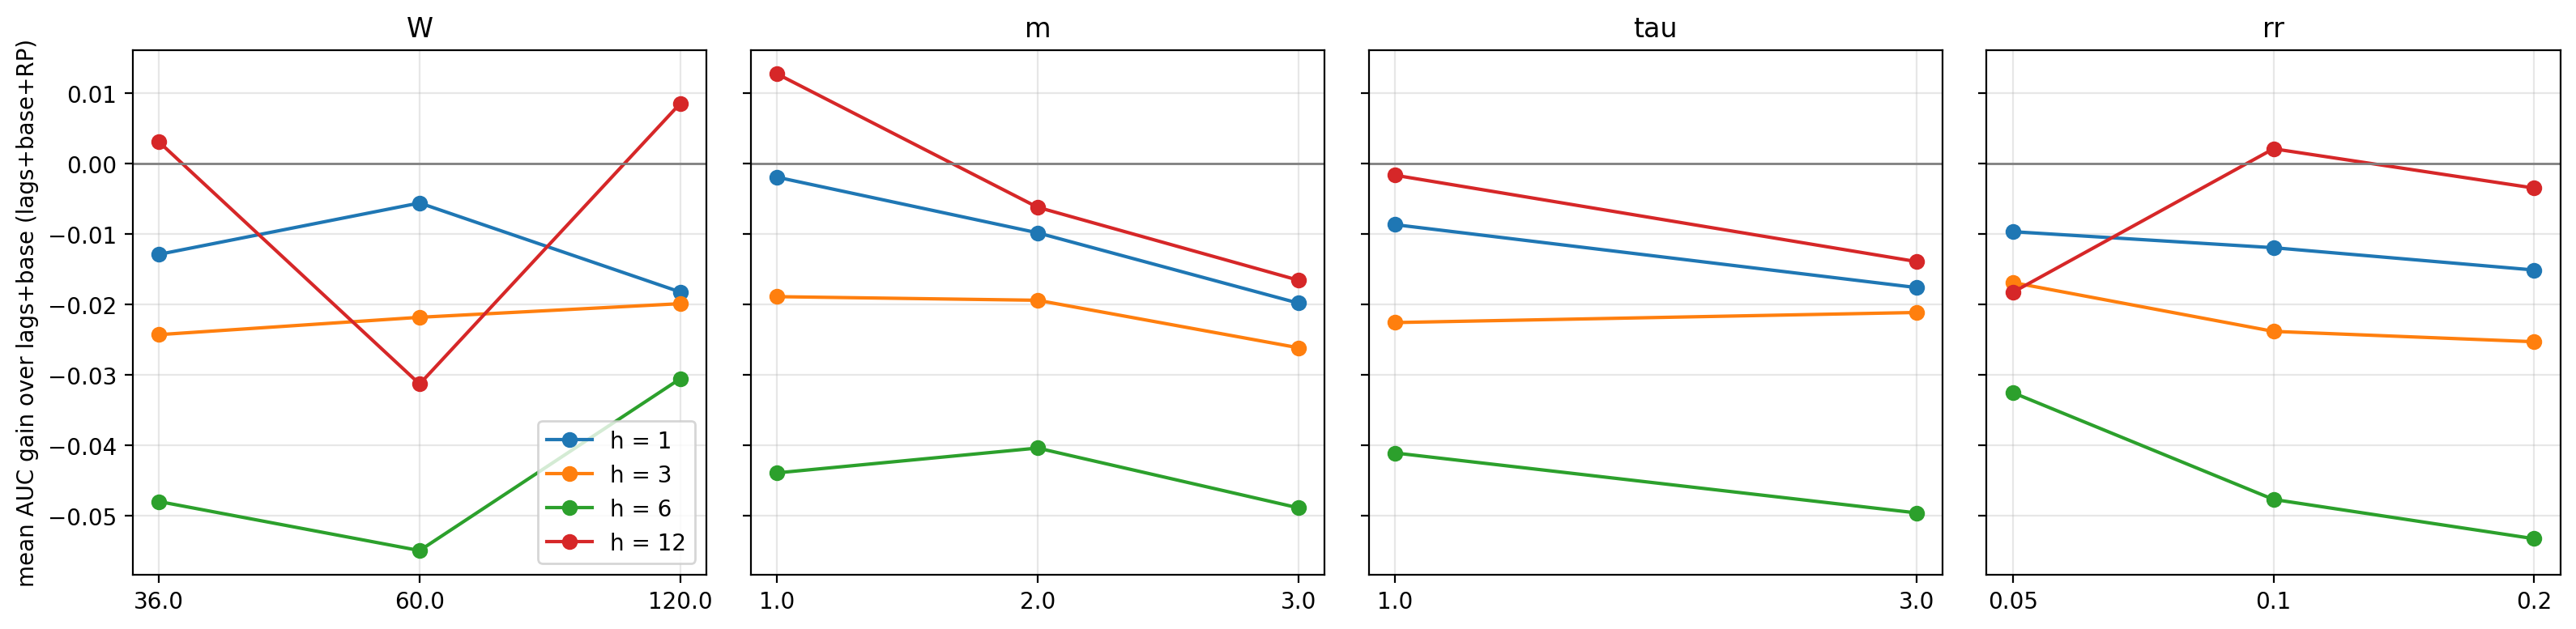

h                    1         3         6         12
factor level                                         
W      36.00  -0.012878 -0.024272 -0.047960  0.003100
       60.00  -0.005583 -0.021809 -0.054920 -0.031283
       120.00 -0.018224 -0.019876 -0.030521  0.008559
m      1.00   -0.001917 -0.018880 -0.043896  0.012758
       2.00   -0.009818 -0.019394 -0.040367 -0.006189
       3.00   -0.019794 -0.026130 -0.048853 -0.016544
tau    1.00   -0.008656 -0.022558 -0.041066 -0.001638
       3.00   -0.017586 -0.021127 -0.049569 -0.013896
rr     0.05   -0.009655 -0.016871 -0.032498 -0.018267
       0.10   -0.011931 -0.023808 -0.047662  0.002110
       0.20   -0.015099 -0.025278 -0.053241 -0.003467

In [18]:
combined = screen[screen.feature_set == "lags+base+RP"]
marginal = pd.concat({f: combined.pivot_table(index=f, columns="h", values="dauc", aggfunc="mean") for f in KEYS},
                     names=["factor", "level"])

fig, axes = plt.subplots(1, len(KEYS), figsize=(4 * len(KEYS), 4), sharey=True)
for ax, f in zip(axes, KEYS):
    g = marginal.loc[f]
    for h in HORIZONS:
        ax.plot(range(len(g)), g[h], "o-", label=f"h = {h}")
    ax.set_xticks(range(len(g)), [str(v) for v in g.index])
    ax.axhline(0, color="grey", lw=1)
    ax.set_title(f)
    ax.grid(alpha=0.3)
axes[0].set_ylabel("mean AUC gain over lags+base (lags+base+RP)")
axes[0].legend()
fig.tight_layout()
plt.show()
marginal

## 11. Final test on 2000–2026

Run once. Do not use this section to choose parameters.

In [19]:
picks = (screen.sort_values(["auc", *KEYS], ascending=[False] + [True] * len(KEYS))
         .groupby(["h", "feature_set"]).head(1).set_index(["h", "feature_set"]))

rows = []
for h in HORIZONS:
    y = targets[h]
    for name, s in no_fit_baselines(h, *FINAL_YEARS).items():
        rows.append({"h": h, "model": name, "screen_auc": baselines_screen.loc[(h, name), "auc"],
                     "final_auc": s["auc"], "final_acc": s["acc"]})
    base_scores, base_pred = evaluate(lag_base_features[h], h, *FINAL_YEARS)
    rows.append({"h": h, "model": "lags+base", "screen_auc": baselines_screen.loc[(h, "lags+base"), "auc"],
                 "final_auc": base_scores["auc"], "final_acc": base_scores["acc"], "n_test": base_scores["n_test"]})
    candidates = [("lagged values", {}, baselines_screen.loc[(h, "lagged values"), "auc"], lagged_values())]
    for fs in FEATURE_SETS:
        r = picks.loc[(h, fs)]
        cfg = tuple(r[KEYS])
        candidates.append((fs, dict(zip(KEYS, cfg)), r.auc, feature_matrix(cfg, h, fs)))
    for name, cfg, screen_auc, X in candidates:
        scores, pred = evaluate(X, h, *FINAL_YEARS)
        gain, lo, hi = auc_gain(pred, base_pred, y)
        rows.append({"h": h, "model": name, **cfg, "screen_auc": screen_auc, "final_auc": scores["auc"],
                     "final_acc": scores["acc"], "n_test": scores["n_test"],
                     "gain vs lags+base": gain, "gain lo": lo, "gain hi": hi})

final = pd.DataFrame(rows).set_index(["h", "model"])[
    KEYS + ["screen_auc", "final_auc", "final_acc", "n_test", "gain vs lags+base", "gain lo", "gain hi"]]
final

W    m  tau  ...  gain vs lags+base   gain lo   gain hi
h  model                              ...                                       
1  majority            NaN  NaN  NaN  ...                NaN       NaN       NaN
   persistence         NaN  NaN  NaN  ...                NaN       NaN       NaN
   base-effect rule    NaN  NaN  NaN  ...                NaN       NaN       NaN
   lags+base           NaN  NaN  NaN  ...                NaN       NaN       NaN
   lagged values       NaN  NaN  NaN  ...          -0.123575 -0.174535 -0.075696
   RP                 60.0  2.0  1.0  ...          -0.362021 -0.451447 -0.270089
   lags+base+analog   36.0  2.0  1.0  ...          -0.002849 -0.010230  0.005043
   lags+base+window   60.0  2.0  3.0  ...           0.000317 -0.012137  0.012819
   lags+base+RP      120.0  2.0  1.0  ...           0.009378 -0.004642  0.023239
3  majority            NaN  NaN  NaN  ...                NaN       NaN       NaN
   persistence         NaN  NaN  NaN  ...                NaN       NaN       NaN
   base-effect rule    NaN  NaN  NaN  ...                NaN       NaN       NaN
   lags+base           NaN  NaN  NaN  ...                NaN       NaN       NaN
   lagged values       NaN  NaN  NaN  ...          -0.171454 -0.227831 -0.114340
   RP                 60.0  2.0  1.0  ...          -0.259905 -0.379508 -0.156728
   lags+base+analog   36.0  3.0  1.0  ...          -0.000200 -0.009847  0.010451
   lags+base+window  120.0  2.0  1.0  ...           0.002123 -0.022422  0.025222
   lags+base+RP      120.0  2.0  1.0  ...          -0.005528 -0.038185  0.023799
6  majority            NaN  NaN  NaN  ...                NaN       NaN       NaN
   persistence         NaN  NaN  NaN  ...                NaN       NaN       NaN
   base-effect rule    NaN  NaN  NaN  ...                NaN       NaN       NaN
   lags+base           NaN  NaN  NaN  ...                NaN       NaN       NaN
   lagged values       NaN  NaN  NaN  ...          -0.201870 -0.258868 -0.144884
   RP                 60.0  2.0  1.0  ...          -0.211385 -0.331075 -0.097234
   lags+base+analog   36.0  3.0  1.0  ...          -0.017841 -0.039736  0.002591
   lags+base+window  120.0  1.0  1.0  ...           0.025593 -0.050806  0.099951
   lags+base+RP      120.0  2.0  1.0  ...           0.048683 -0.024746  0.129221
12 majority            NaN  NaN  NaN  ...                NaN       NaN       NaN
   persistence         NaN  NaN  NaN  ...                NaN       NaN       NaN
   base-effect rule    NaN  NaN  NaN  ...                NaN       NaN       NaN
   lags+base           NaN  NaN  NaN  ...                NaN       NaN       NaN
   lagged values       NaN  NaN  NaN  ...          -0.056757 -0.096912 -0.016711
   RP                 60.0  3.0  1.0  ...          -0.139152 -0.329728  0.056191
   lags+base+analog   36.0  3.0  3.0  ...          -0.004554 -0.038222  0.029984
   lags+base+window  120.0  2.0  1.0  ...           0.089437 -0.007208  0.190586
   lags+base+RP      120.0  2.0  1.0  ...           0.073919 -0.023529  0.175484

[36 rows x 11 columns]